FIRST 5 ROWS
       Date/Time  Temp_C  Dew Point Temp_C  Rel Hum_%  Wind Speed_km/h  \
0  1/1/2012 0:00    -1.8              -3.9         86                4   
1  1/1/2012 1:00    -1.8              -3.7         87                4   
2  1/1/2012 2:00    -1.8              -3.4         89                7   
3  1/1/2012 3:00    -1.5              -3.2         88                6   
4  1/1/2012 4:00    -1.5              -3.3         88                7   

   Visibility_km  Press_kPa               Weather  
0            8.0     101.24                   Fog  
1            8.0     101.24                   Fog  
2            4.0     101.26  Freezing Drizzle,Fog  
3            4.0     101.27  Freezing Drizzle,Fog  
4            4.8     101.23                   Fog  

DATASET SHAPE: (8784, 8)

COLUMN NAMES: ['Date/Time', 'Temp_C', 'Dew Point Temp_C', 'Rel Hum_%', 'Wind Speed_km/h', 'Visibility_km', 'Press_kPa', 'Weather']

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 8784 entries

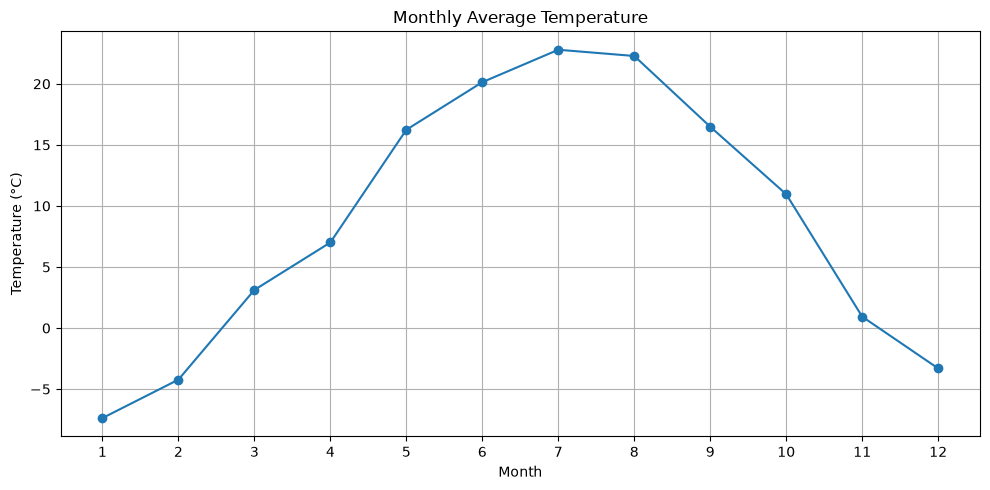

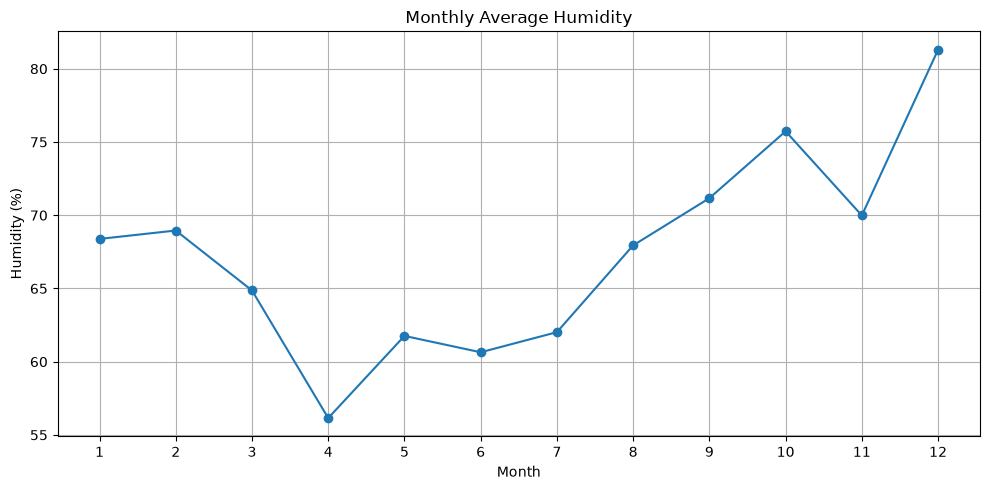

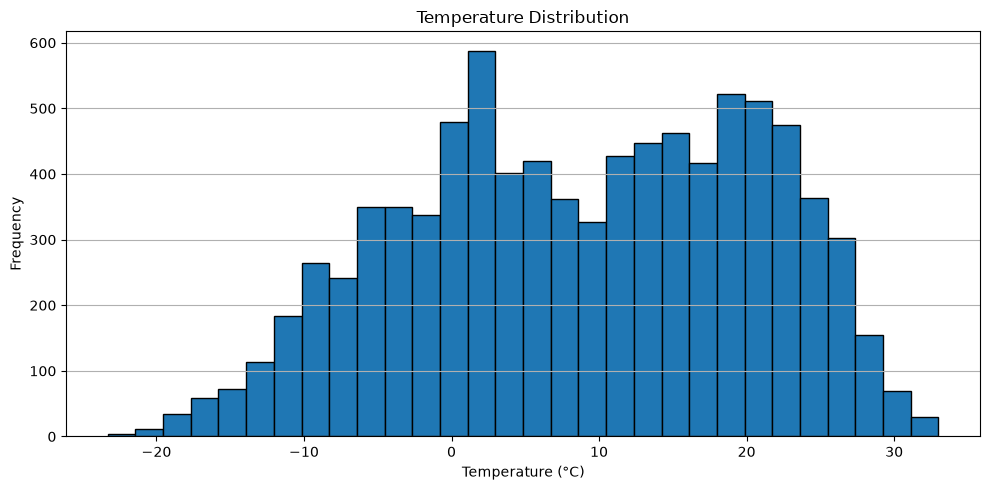


TOP 10 WEATHER CONDITIONS
Weather
Mainly Clear     2106
Mostly Cloudy    2069
Cloudy           1728
Clear            1326
Snow              390
Rain              306
Rain Showers      188
Fog               150
Rain,Fog          116
Drizzle,Fog        80
Name: count, dtype: int64


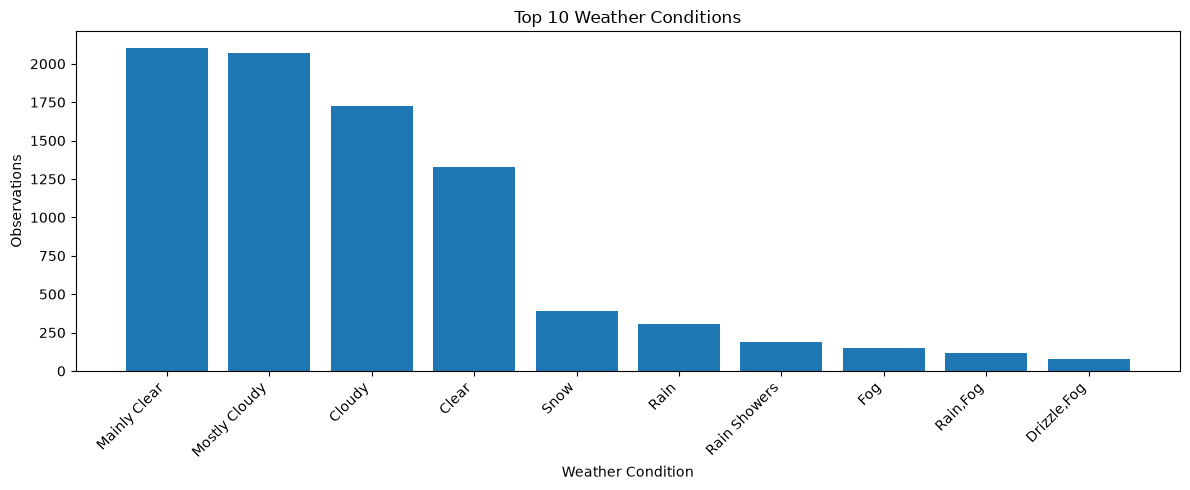

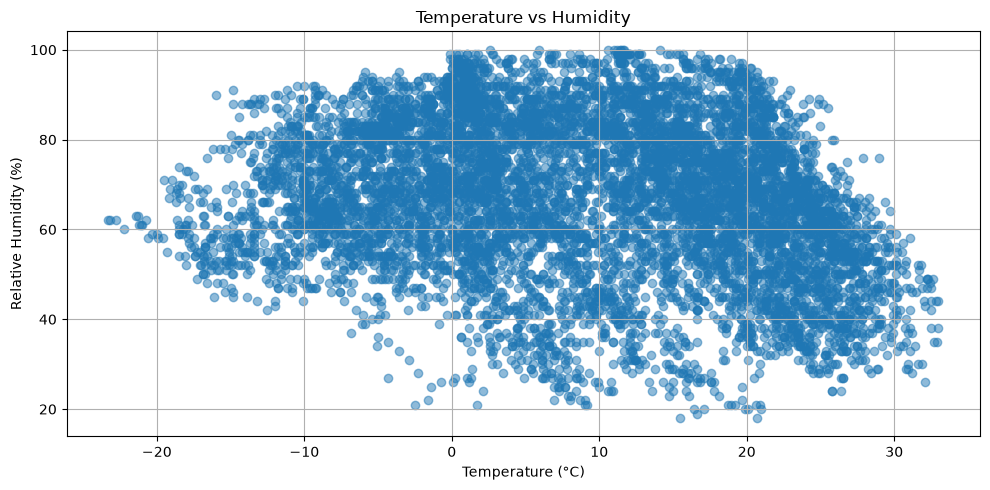

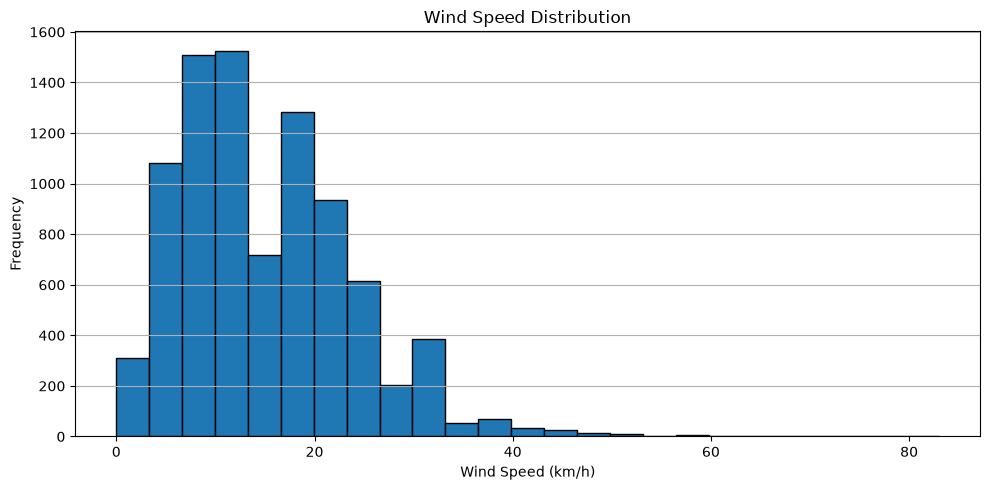

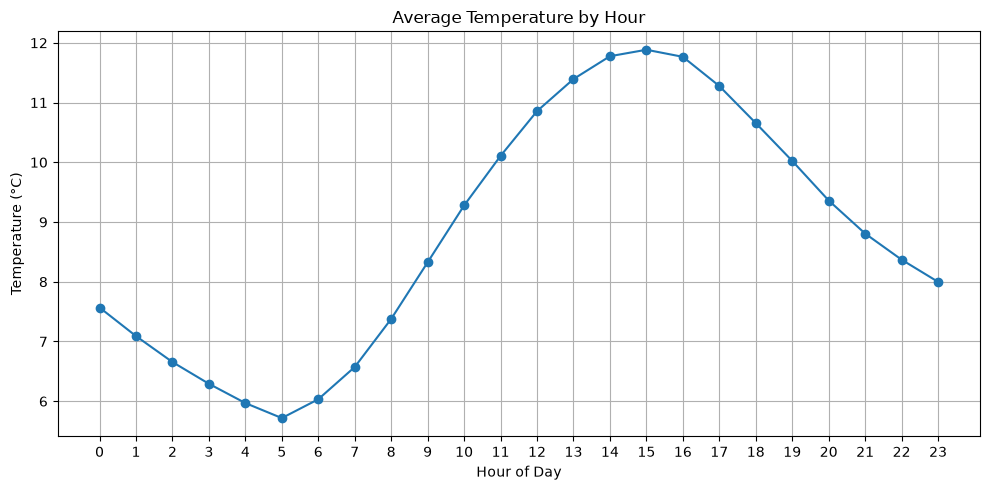


CORRELATION MATRIX
                  Temp_C  Dew Point Temp_C  Rel Hum_%  Wind Speed_km/h  \
Temp_C              1.00              0.93      -0.22            -0.06   
Dew Point Temp_C    0.93              1.00       0.14            -0.10   
Rel Hum_%          -0.22              0.14       1.00            -0.09   
Wind Speed_km/h    -0.06             -0.10      -0.09             1.00   
Visibility_km       0.27              0.05      -0.63             0.00   
Press_kPa          -0.24             -0.32      -0.23            -0.36   
Year                 NaN               NaN        NaN              NaN   
Month               0.22              0.30       0.23            -0.03   
Day                 0.01              0.01      -0.01             0.07   
Hour                0.11              0.02      -0.24             0.08   

                  Visibility_km  Press_kPa  Year  Month   Day  Hour  
Temp_C                     0.27      -0.24   NaN   0.22  0.01  0.11  
Dew Point Temp_C         

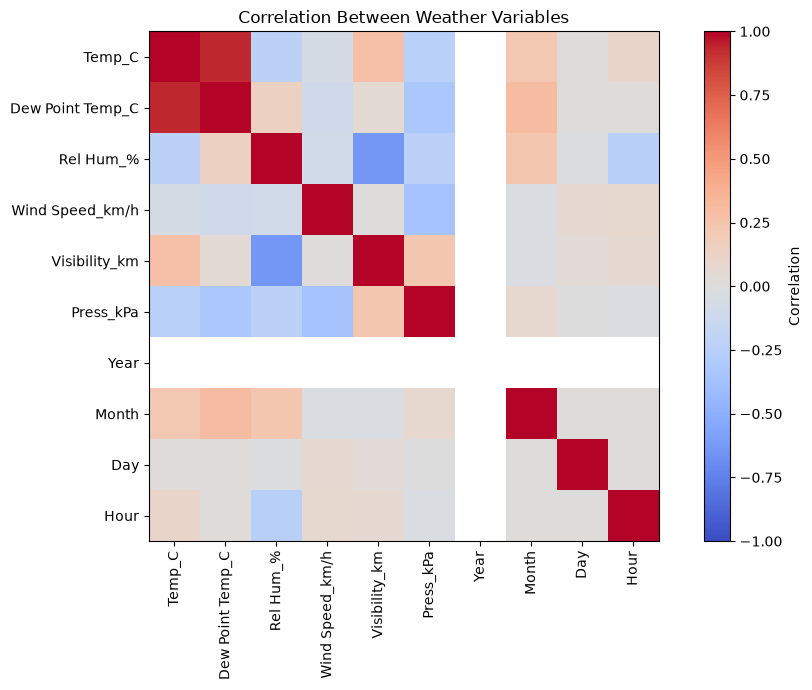


       WEATHER DATA ANALYSIS REPORT
Total Records: 8784
Total Columns: 13
Date Range: 2012-01-01 00:00:00 to 2012-12-31 23:00:00
Average Temperature: 8.8 °C
Highest Temperature: 33.0 °C
Lowest Temperature: -23.3 °C
Average Humidity: 67.43 %
Average Wind Speed: 14.95 km/h
Average Visibility: 27.66 km
Average Pressure: 101.05 kPa
Most Common Weather: Mainly Clear
Missing Values Remaining: 0
ANALYSIS COMPLETED SUCCESSFULLY!


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. LOAD DATASET
# ==========================================

df = pd.read_csv("Weather Data.csv")

print("FIRST 5 ROWS")
print(df.head())

print("\nDATASET SHAPE:", df.shape)
print("\nCOLUMN NAMES:", df.columns.tolist())

print("\nDATASET INFORMATION")
df.info()

print("\nSTATISTICAL SUMMARY")
print(df.describe())

# ==========================================
# 2. DATA CLEANING
# ==========================================

df = df.copy()
df.columns = df.columns.str.strip()

df["Date/Time"] = pd.to_datetime(
    df["Date/Time"], errors="coerce"
)

print("\nMISSING VALUES BEFORE CLEANING")
print(df.isnull().sum())

print("\nDUPLICATE ROWS:", df.duplicated().sum())

df = df.drop_duplicates()
df = df.dropna(subset=["Date/Time"])

df = df.sort_values("Date/Time").reset_index(drop=True)

print("\nDATASET SHAPE AFTER CLEANING:", df.shape)

# ==========================================
# 3. FEATURE ENGINEERING
# ==========================================

df["Year"] = df["Date/Time"].dt.year
df["Month"] = df["Date/Time"].dt.month
df["Month_Name"] = df["Date/Time"].dt.month_name()
df["Day"] = df["Date/Time"].dt.day
df["Hour"] = df["Date/Time"].dt.hour

print("\nUPDATED DATASET")
print(df.head())

# ==========================================
# 4. BASIC STATISTICAL ANALYSIS
# ==========================================

print("\nBASIC WEATHER STATISTICS")

weather_columns = [
    "Temp_C",
    "Dew Point Temp_C",
    "Rel Hum_%",
    "Wind Speed_km/h",
    "Visibility_km",
    "Press_kPa"
]

for col in weather_columns:
    print(f"\n{col}")
    print("Mean:", round(df[col].mean(), 2))
    print("Maximum:", df[col].max())
    print("Minimum:", df[col].min())

print("\nMOST COMMON WEATHER CONDITION")
print(df["Weather"].mode()[0])

# ==========================================
# 5. MONTHLY TEMPERATURE ANALYSIS
# ==========================================

monthly_temp = df.groupby("Month")["Temp_C"].mean()

plt.figure(figsize=(10, 5))
plt.plot(monthly_temp.index, monthly_temp.values, marker="o")
plt.title("Monthly Average Temperature")
plt.xlabel("Month")
plt.ylabel("Temperature (°C)")
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()

# ==========================================
# 6. MONTHLY HUMIDITY ANALYSIS
# ==========================================

monthly_humidity = df.groupby("Month")["Rel Hum_%"].mean()

plt.figure(figsize=(10, 5))
plt.plot(monthly_humidity.index, monthly_humidity.values, marker="o")
plt.title("Monthly Average Humidity")
plt.xlabel("Month")
plt.ylabel("Humidity (%)")
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()

# ==========================================
# 7. TEMPERATURE DISTRIBUTION
# ==========================================

plt.figure(figsize=(10, 5))
plt.hist(df["Temp_C"].dropna(), bins=30, edgecolor="black")
plt.title("Temperature Distribution")
plt.xlabel("Temperature (°C)")
plt.ylabel("Frequency")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

# ==========================================
# 8. TOP 10 WEATHER CONDITIONS
# ==========================================

weather_counts = df["Weather"].value_counts().head(10)

print("\nTOP 10 WEATHER CONDITIONS")
print(weather_counts)

plt.figure(figsize=(12, 5))
plt.bar(weather_counts.index, weather_counts.values)
plt.title("Top 10 Weather Conditions")
plt.xlabel("Weather Condition")
plt.ylabel("Observations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# ==========================================
# 9. TEMPERATURE VS HUMIDITY
# ==========================================

plt.figure(figsize=(10, 5))
plt.scatter(df["Temp_C"], df["Rel Hum_%"], alpha=0.5)
plt.title("Temperature vs Humidity")
plt.xlabel("Temperature (°C)")
plt.ylabel("Relative Humidity (%)")
plt.grid(True)
plt.tight_layout()
plt.show()

# ==========================================
# 10. WIND SPEED DISTRIBUTION
# ==========================================

plt.figure(figsize=(10, 5))
plt.hist(df["Wind Speed_km/h"].dropna(), bins=25, edgecolor="black")
plt.title("Wind Speed Distribution")
plt.xlabel("Wind Speed (km/h)")
plt.ylabel("Frequency")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

# ==========================================
# 11. HOURLY TEMPERATURE ANALYSIS
# ==========================================

hourly_temp = df.groupby("Hour")["Temp_C"].mean()

plt.figure(figsize=(10, 5))
plt.plot(hourly_temp.index, hourly_temp.values, marker="o")
plt.title("Average Temperature by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Temperature (°C)")
plt.xticks(range(0, 24))
plt.grid(True)
plt.tight_layout()
plt.show()

# ==========================================
# 12. CORRELATION ANALYSIS
# ==========================================

numeric_df = df.select_dtypes(include=np.number)
correlation = numeric_df.corr()

print("\nCORRELATION MATRIX")
print(correlation.round(2))

plt.figure(figsize=(10, 7))
plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Correlation Between Weather Variables")
plt.tight_layout()
plt.show()

# ==========================================
# 13. FINAL ANALYSIS REPORT
# ==========================================

print("\n" + "=" * 40)
print("       WEATHER DATA ANALYSIS REPORT")
print("=" * 40)

print("Total Records:", len(df))
print("Total Columns:", len(df.columns))

print(
    "Date Range:",
    df["Date/Time"].min(),
    "to",
    df["Date/Time"].max()
)

print("Average Temperature:",
      round(df["Temp_C"].mean(), 2), "°C")

print("Highest Temperature:",
      round(df["Temp_C"].max(), 2), "°C")

print("Lowest Temperature:",
      round(df["Temp_C"].min(), 2), "°C")

print("Average Humidity:",
      round(df["Rel Hum_%"].mean(), 2), "%")

print("Average Wind Speed:",
      round(df["Wind Speed_km/h"].mean(), 2), "km/h")

print("Average Visibility:",
      round(df["Visibility_km"].mean(), 2), "km")

print("Average Pressure:",
      round(df["Press_kPa"].mean(), 2), "kPa")

print("Most Common Weather:",
      df["Weather"].mode()[0])

print("Missing Values Remaining:", df.isnull().sum().sum())

print("=" * 40)
print("ANALYSIS COMPLETED SUCCESSFULLY!")
